# Joint VAE for MNIST and SVHN

In this notebook we build a **multi-view VAE** (a joint VAE). The model sees two views of the same thing:

- **View 1:** a handwritten digit from MNIST (gray image, resized to 32x32)
- **View 2:** a house number digit from SVHN (color image, 32x32)

Both images in a pair show the **same digit** (for example, a "7" from MNIST and a "7" from SVHN). They are different images, they only share the label.

The idea is that the model learns **one shared latent space** `z`. From `z` we can build both an MNIST image and an SVHN image. This lets us do cool things like turning an MNIST digit into an SVHN digit (cross-domain generation).

**Plan:**

1. Build the paired dataset (MNIST + SVHN with the same label)
2. Write the model (one encoder and one decoder per view, plus a way to join the views)
3. Train the model
4. See reconstructions, random generation and cross-domain generation
5. Look at the latent space with t-SNE

In [15]:
import os
import time
import numpy as np
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# We fix the seeds so the results are easier to repeat
torch.manual_seed(0)
np.random.seed(0)

# Universal device selection: CUDA (NVIDIA / Colab) -> MPS (Apple Silicon) -> CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print("Using device:", device)


Using device: mps


## Part 1: Building the paired dataset

First we download MNIST and SVHN with the torchvision package. 

Then we build the pairs. The two datasets are not related, so we have to create the pairs ourselves:

- For every MNIST image, we look at its label (for example 3).
- We pick a **random** SVHN image that also has label 3.
- The two images form one sample `X = (MNIST image, SVHN image)`.

We do this once at the start, so the pairs stay the same during training.

In [16]:
data_dir = './data'   # the datasets will be downloaded here

mnist_tf = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),      # 1 channel
])

svhn_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # 3 channels
])

mnist_train = datasets.MNIST(data_dir, train=True, download=True, transform=mnist_tf)
mnist_test  = datasets.MNIST(data_dir, train=False, download=True, transform=mnist_tf)

svhn_train = datasets.SVHN(data_dir, split='train', download=True, transform=svhn_tf)
svhn_test  = datasets.SVHN(data_dir, split='test', download=True, transform=svhn_tf)

print("MNIST train:", mnist_train.data.shape, " MNIST test:", mnist_test.data.shape)
print("SVHN train: ", svhn_train.data.shape, " SVHN test: ", svhn_test.data.shape)

MNIST train: torch.Size([60000, 28, 28])  MNIST test: torch.Size([10000, 28, 28])
SVHN train:  (73257, 3, 32, 32)  SVHN test:  (26032, 3, 32, 32)


In [17]:
x_mnist, y_mnist = mnist_train[0]
x_svhn, y_svhn = svhn_train[0]

print(x_mnist.shape)
print(x_svhn.shape)

torch.Size([1, 32, 32])
torch.Size([3, 32, 32])


Some notes about the data:

- MNIST images are 28x28 with one channel and SVHN images are 32x32 with 3 color channels. With the transforms, both are resized to **32x32**, so the two views have the same size. SVHN is already 32x32, so for SVHN the resize does nothing. MNIST only grows a little (from 28 to 32).
- `ToTensor` changes the pixel values to [0, 1], and `Normalize` with mean 0.5 and std 0.5 moves them to [-1, 1]. This range matches the `tanh` output of the decoders.
- The `print` shows the size of the **original** data (before the transforms). The transforms are applied later, when we read each image.
- In torchvision, the SVHN digit "0" has label 0 (not 10), so the labels match the MNIST ones.

In [18]:
class PairedMNISTSVHN(Dataset):

    def __init__(self, mnist, svhn, seed=0):
        self.rng = np.random.RandomState(seed)

        self.mnist = mnist
        self.svhn = svhn

        self.mnist_labels = np.array(mnist.targets)
        self.svhn_labels = np.array(svhn.labels)

        # For every digit, we save the positions of all the SVHN images with that digit
        svhn_pos_by_digit = {d: np.where(self.svhn_labels == d)[0] for d in range(10)}

        self.svhn_pos_by_digit = svhn_pos_by_digit

        # We make the first pairs
        self.reshuffle_pairs()

    def reshuffle_pairs(self):
        # For every MNIST image, we choose a random SVHN image with the same label.
        # We can call this function again to make NEW pairs (same digits, different SVHN images).
        self.svhn_index = np.zeros(len(self.mnist_labels), dtype=int)
        for d in range(10):
            where_digit = np.where(self.mnist_labels == d)[0]          
            self.svhn_index[where_digit] = self.rng.choice(self.svhn_pos_by_digit[d], size=len(where_digit))

        assert (self.mnist_labels == self.svhn_labels[self.svhn_index]).all()

    def __len__(self):
        return len(self.mnist_labels)

    def __getitem__(self, i):
        x_mnist, label = self.mnist[i]                  # image already transformed, and its label
        x_svhn, _ = self.svhn[self.svhn_index[i]]       # the SVHN image paired with this MNIST image
        return x_mnist, x_svhn, int(label)

In [19]:
train_ds = PairedMNISTSVHN(mnist_train, svhn_train, seed=0)
test_ds  = PairedMNISTSVHN(mnist_test,  svhn_test,  seed=1)

print("Number of training pairs:", len(train_ds))
print("Number of test pairs:", len(test_ds))

batch_size = 128

trainloader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True)
testloader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

Number of training pairs: 60000
Number of test pairs: 10000


/var/folders/2x/j6wk2mcs3r5_v54m5lthywdc0000gn/T/ipykernel_65556/3334936964.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  self.mnist_labels = np.array(mnist.targets)


Let's look at some pairs to check that the dataset is correct. We take one batch and show the first 16 MNIST images and the first 16 SVHN images. The image number k in the first grid and the image number k in the second grid must show the **same digit** (the labels `y` are printed).

In [20]:
def imshow(img):
    if torch.is_tensor(img):
        img = img.detach().cpu()
    img = img / 2 + 0.5                       
    npimg = img.numpy()
    if npimg.shape[0] == 1:                   
        npimg = np.repeat(npimg, 3, axis=0)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

def grid(imgs, nrow=8):
    if torch.is_tensor(imgs):
        imgs = imgs.detach().cpu()
    if imgs.shape[1] == 1:
        imgs = imgs.repeat(1, 3, 1, 1)
    imshow(torchvision.utils.make_grid(imgs, nrow=nrow))


torch.Size([128, 1, 32, 32]) torch.Size([128, 3, 32, 32]) tensor([6, 8, 8, 7, 8, 0, 0, 5, 6, 0, 0, 3, 5, 8, 1, 6])


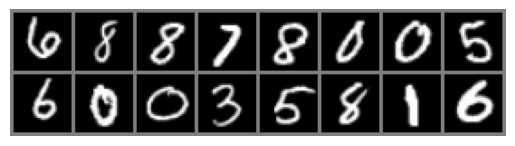

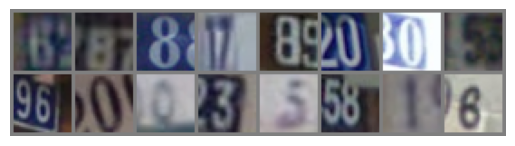

In [21]:
x_m, x_s, y = next(iter(trainloader))

print(x_m.shape, x_s.shape, y[:16])

grid(x_m[:16])
grid(x_s[:16])

## Part 2: The multi-view VAE

### Main idea

A normal VAE has one encoder and one decoder. Here we have **two of each**, one pair for MNIST and one pair for SVHN. The latent vector of each view has two parts, `z = [z_shared | w_private]`:

- **`z_shared`** (32 numbers) is the part that both views have in common. Both encoders write into the **same** shared space, and both decoders read from it. This is why we can go from one view to the other. Since the pairs only share the digit, `z_shared` should mostly be the digit.
- **`w_private`** is the part of each view alone: its style (color, background, stroke). MNIST has 1 private number and SVHN has 4. They are kept small on purpose. If the private part is big, the decoder can copy the digit from it and ignore `z_shared`, and then cross-domain generation fails.

### How do we join the two views?

Each encoder gives its own opinion about `z_shared` (we call each opinion an *expert*). We need one single answer, and there are two classic ways. They are applied **only** to `z_shared`. Each private part comes only from the encoder of its own view.

- **Product of Experts (PoE):** we multiply the opinions. The result is a Gaussian that is sharper than both experts. Intuitively, the experts have to **agree**, and the expert that is more sure (less variance) has more weight. We also add a "prior expert" (a standard normal) as in the original paper.
- **Mixture of Experts (MoE):** we mix the opinions. For each sample we pick one expert (MNIST or SVHN) with equal chance and take `z_shared` from it. Then we try to rebuild **both** images from it.

The code supports both. You only need to change the variable `MODE` below (`'moe'` or `'poe'`). All the final results of this notebook are with PoE.

### Training loss

The loss has the same two parts as in a normal VAE, plus one extra term:

1. **Reconstruction error:** the Gaussian log-likelihood (the function `eval_Gaussian_LL` from the CelebA lab) with a minus sign to make it a loss. The fixed variance is `var_x_mnist = 0.1` for MNIST and `var_x_svhn = 0.05` for SVHN. The MNIST error is multiplied by 3 to compensate that it has 1 channel and SVHN has 3. This loss can be **negative**: the Gaussian likelihood has a constant that depends on `var_x`, and it makes the loss lower than zero when the squared error is small. So the absolute value of the loss is not meaningful, and it cannot be compared between models with different `var_x` or different private sizes.
2. **KL term:** how far the encoder outputs are from the standard normal prior. Its weight `beta` grows from 0.2 to 1.0 during the first 5 epochs (KL annealing), so the decoders can learn the details before the prior smooths everything.
3. **Alignment term:** it pulls the two shared means of the same pair together, `align_weight * 0.5 * ||mu_shared_mnist - mu_shared_svhn||^2`.

For PoE we train three times in each step: using both views, using only MNIST, and using only SVHN. This is important! If we only trained with both views, the model would not know how to work when only one view is given (and we need that for cross-domain generation).

When one view is not given, its decoder still needs a private part. With `missing_private='cross'` (the DMVAE idea) we take it from the **real image of the pair**, so the target image is never unrelated to the input and the decoder is not pushed to output the average image (the gray SVHN of the first versions).

These two classes (`encoder` and `decoder`) follow the same structure as the CelebA lab code: named conv layers (`conv1` to `conv4` / `tconv1` to `tconv4`), a `relu` activation, a `softplus` for the variance, and a `tanh` for the image output. The encoder also has an `encode_and_sample` method and the decoder has a `decode` method. Our images are 32x32 (half the size of the 64x64 CelebA images from the notebook we've seen in class), so we use one convolution less: four convolutions that make the image smaller step by step (32 -> 16 -> 8 -> 4 -> 1). We only change the number of input channels (1 for MNIST, 3 for SVHN).

In [22]:
class encoder(nn.Module):

    def __init__(self, dimz, channels=3):
        super().__init__()

        self.dimz = dimz    # dimz is k, the dimension of the latent space

        # conv1: 32x32 -> 16x16
        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32, kernel_size=4, stride=2, padding=1)
        # conv2: 16x16 -> 8x8
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2, padding=1)
        # conv3: 8x8 -> 4x4
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1)
        # conv4: 4x4 -> 1x1
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=1, padding=0)

        self.relu = nn.ReLU()
        self.linear = nn.Linear(256, dimz * 2)
        self.softplus = nn.Softplus()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = x.view(x.shape[0], -1)
        x = self.linear(x)
        return x

    def encode_and_sample(self, x, flag_sample=True):
        # Runs the network and splits the output into mean and variance.
        # If flag_sample is True, we also return one sample of z (reparametrization trick).

        out = self.forward(x)

        mu = out[:, :self.dimz]
        var = self.softplus(out[:, self.dimz:]) + 1e-6   # small number to avoid zero variance

        if flag_sample:
            std = torch.sqrt(var)
            eps = torch.randn_like(std)
            sample = mu + eps * std
        else:
            sample = mu

        return mu, var, sample

In [23]:
class decoder(nn.Module):

    def __init__(self, dimz, channels=3):
        super().__init__()

        self.linear = nn.Linear(dimz, 256)
        self.relu = nn.ReLU()
        self.tanh = nn.Tanh()

        # tconv1: 1x1 -> 4x4
        self.tconv1 = nn.ConvTranspose2d(256, 128, kernel_size=4, stride=1, padding=0)
        # tconv2: 4x4 -> 8x8
        self.tconv2 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1)
        # tconv3: 8x8 -> 16x16
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1)
        # tconv4: 16x16 -> 32x32, and down to the number of channels of this view
        self.tconv4 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2, padding=1)

    def forward(self, z):
        x = self.relu(self.linear(z).view(-1, 256, 1, 1))
        x = self.relu(self.tconv1(x))
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))
        x = self.tanh(self.tconv4(x))
        return x

    def decode(self, z):
        # Just a clearer name for forward, like in the CelebA example
        return self.forward(z)

Now some small helper functions:

- `sample_z`: the reparametrization trick. We sample `z` as `mean + std * noise`, so we can still do backpropagation.
- `kl_to_prior`: the KL term, summed over the batch. 
- `eval_Gaussian_LL`: the same function as in the CelebA lab. It gives the Gaussian log-likelihood of the real images given the reconstructed ones. It works for any number of channels, so we use it for both MNIST (1 channel) and SVHN (3 channels). To get a loss we use its negative value.
- `product_of_experts`: joins several Gaussian experts into one. It also adds the prior expert.

In [24]:
def sample_z(mu, var):
    # z = mean + std * noise
    return mu + torch.sqrt(var) * torch.randn_like(mu)


def kl_to_prior(mu, var):
    # KL between N(mu, var) and N(0, 1), summed over the batch and the latent dimensions
    return -0.5 * torch.sum(1 + torch.log(var) - mu.pow(2) - var)


def eval_Gaussian_LL(x,mu_x,var_x):

    # x is a mini-batch of images. It has dimension [Batch,channels,dimx,dimx]

    # mu_x is a mini-batch of reconstructed images. It has dimension [Batch,channels,dimx,dimx]

    # var_x is a torch constant

    D = x.shape[1] * x.shape[2] * x.shape[3]   # Dimension of the image

    x = x.reshape(-1, D)

    mu_x = mu_x.reshape(-1, D)

    var_x = torch.ones_like(mu_x) * var_x

    # Constant term in the gaussian distribution
    cnt = D * np.log(2 * np.pi) + torch.sum(torch.log(var_x), dim=-1)

    # log-likelihood per datapoint

    logp_data = -0.5 * (cnt + torch.sum((x - mu_x) * var_x ** -1 * (x - mu_x), dim=-1))
    
    # Accumulated Gaussian log-likelihood for all datapoints in the batch
    logp = torch.sum(logp_data)

    return logp,logp_data


def product_of_experts(mus, vars):
    # mus and vars are lists with the mean and variance of each expert.
    # "precision" is just 1 / variance. When we multiply Gaussians, the precisions add up.
    precisions = [1.0 / v for v in vars]
    total_precision = 1.0 + sum(precisions)         # the "1.0" is the prior expert N(0, 1)
    var = 1.0 / total_precision
    mu = var * sum(m * p for m, p in zip(mus, precisions))   # the prior has mean 0, so it adds nothing here
    return mu, var

### The JointVAE class (shared + private latent)

Each view has its own latent vector `z = [z_shared | w_private]`. The private part can have a **different size in each view** (`dimz_private_mnist`, `dimz_private_svhn`). The `encoder` and `decoder` classes do **not** change: each view just receives `dimz = dimz_shared + its private size`, and `JointVAE` splits and recombines the two parts.

- **Shared part `z_shared`:** fused with PoE (or MoE). It should carry what both views have in common: the digit.
- **Private part `w`:** it comes only from the encoder of its own view. It should carry the style (color, background, stroke). It is kept small on purpose, and smaller for MNIST (which has almost no style): a big `w` lets the decoder copy the digit from it and ignore `z_shared`.
- **Alignment term:** `align_weight * 0.5 * ||mu_shared_mnist - mu_shared_svhn||^2` pulls the two shared means together.

When one view is missing in an ELBO term, its private part has to come from somewhere. `missing_private` chooses where:

- `'prior'`: a sample from `N(0, sigma^2 I)`.
- `'shuffle'`: the private part of another image of the batch.
- `'cross'` (DMVAE-style cross-reconstruction, Lee & Pavlovic 2021): the private part of the *real* image of the pair. The target is never unrelated to the input, so the decoder is not pushed towards the conditional mean.

Checkpoints are saved to `joint_vae_<mode>_shared_private<tag>.pth` so the v1 files are never overwritten.

In [25]:
class JointVAE(nn.Module):

    def __init__(self, dimz_shared=32, dimz_private_mnist=1, dimz_private_svhn=4, mode='poe', missing_private='cross',
                 prior_sigma=1.0, align_weight=1.0,
                 var_x_mnist=0.1, var_x_svhn=0.05, beta=1.0,
                 lr=1e-3, epochs=20, save_folder='./', tag='', restore=False):

        super().__init__()
        assert mode in ['moe', 'poe']
        assert missing_private in ['prior', 'shuffle', 'cross']

        self.ds = dimz_shared
        self.dp_m = dimz_private_mnist             # private size of MNIST
        self.dp_s = dimz_private_svhn              # private size of SVHN
        self.dimz_m = dimz_shared + dimz_private_mnist   # what the MNIST encoder / decoder receive
        self.dimz_s = dimz_shared + dimz_private_svhn    # what the SVHN encoder / decoder receive
        self.mode = mode
        self.missing_private = missing_private
        self.prior_sigma = prior_sigma
        self.align_weight = align_weight
        self.var_x_mnist = var_x_mnist
        self.var_x_svhn = var_x_svhn
        self.beta = beta     # weight of the KL term
        self.tag = tag

        # One encoder and one decoder for each view (classes unchanged)
        self.enc_mnist = encoder(self.dimz_m, channels=1)
        self.enc_svhn  = encoder(self.dimz_s, channels=3)
        self.dec_mnist = decoder(self.dimz_m, channels=1)
        self.dec_svhn  = decoder(self.dimz_s, channels=3)

        # training set up
        self.lr = lr
        self.epochs = epochs
        self.save_folder = save_folder
        self.optim = optim.Adam(self.parameters(), self.lr)

        # Device selection (CUDA -> MPS -> CPU)
        self.device = torch.device(
            "cuda" if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available()
            else "cpu"
        )
        self.to(self.device)

        # Safe checkpoint loading
        ckpt = self.ckpt_path()
        if restore and os.path.exists(ckpt):
            self.load_state_dict(torch.load(ckpt, map_location=self.device))
            print(f"Loaded checkpoint from: {ckpt} on [{self.device}]")
        elif restore:
            print(f"Checkpoint not found at {ckpt}. Initializing model from scratch.")

        self.loss_during_training = []
        self.rec_during_training = []
        self.kl_during_training = []
        self.test_loss_during_training = []

    def ckpt_path(self):
        return os.path.join(self.save_folder, f'joint_vae_{self.mode}_shared_private{self.tag}.pth')

    # ------------------------------------------------------------------ encoding
    def _encode_view(self, enc, x):
        # Runs one encoder and splits its output into (shared, private) mean and variance
        mu, var, _ = enc.encode_and_sample(x)
        return mu[:, :self.ds], var[:, :self.ds], mu[:, self.ds:], var[:, self.ds:]

    def _fuse(self, mus, vars_):
        # PoE multiplies the experts (and adds the prior expert). MoE uses ONE expert at a time.
        if self.mode == 'poe':
            return product_of_experts(mus, vars_)
        return mus[0], vars_[0]

    def encode_mean(self, x_mnist=None, x_svhn=None):
        # Mean of the SHARED latent for the views that we give (one or both).
        mus, vars_ = [], []
        if x_mnist is not None:
            mu, var, _, _ = self._encode_view(self.enc_mnist, x_mnist)
            mus.append(mu); vars_.append(var)
        if x_svhn is not None:
            mu, var, _, _ = self._encode_view(self.enc_svhn, x_svhn)
            mus.append(mu); vars_.append(var)
        if self.mode == 'poe':
            return product_of_experts(mus, vars_)[0]
        # MoE with both views: the average is a point MoE never sees in training.
        # It is only used for the "joint" t-SNE panel. For reconstruction use reconstruct().
        return torch.stack(mus).mean(dim=0)

    # ------------------------------------------------------------------ decoding
    def decode(self, z_shared, w_mnist, w_svhn):
        return (self.dec_mnist.decode(torch.cat([z_shared, w_mnist], dim=1)),
                self.dec_svhn.decode(torch.cat([z_shared, w_svhn], dim=1)))

    def reconstruct(self, x_mnist, x_svhn):
        # Reconstruction of a real pair. Each view keeps its own private mean.
        mu_m, var_m, wm, _ = self._encode_view(self.enc_mnist, x_mnist)
        mu_s, var_s, ws, _ = self._encode_view(self.enc_svhn, x_svhn)
        if self.mode == 'poe':
            z, _ = product_of_experts([mu_m, mu_s], [var_m, var_s])
            z_m, z_s = z, z
        else:
            # MoE fix: one expert per view (averaging the experts gave gray SVHN)
            z_m, z_s = mu_m, mu_s
        return (self.dec_mnist.decode(torch.cat([z_m, wm], dim=1)),
                self.dec_svhn.decode(torch.cat([z_s, ws], dim=1)))

    def translate(self, x_mnist=None, x_svhn=None, w=None):
        # Cross-domain generation. Exactly one input view.
        # The shared part comes from the input view; the private part of the TARGET view
        # comes from the prior (or from w, e.g. to fix a style).
        assert (x_mnist is None) != (x_svhn is None), "give exactly one view"
        if x_mnist is not None:
            z = self.encode_mean(x_mnist=x_mnist)
            if w is None:
                w = torch.randn(z.shape[0], self.dp_s, device=z.device)      # target = SVHN
            return self.dec_svhn.decode(torch.cat([z, w], dim=1))
        z = self.encode_mean(x_svhn=x_svhn)
        if w is None:
            w = torch.randn(z.shape[0], self.dp_m, device=z.device)          # target = MNIST
        return self.dec_mnist.decode(torch.cat([z, w], dim=1))

    def sample(self, n):
        # Generation from the prior: z_shared, w_mnist and w_svhn are all drawn from N(0, I)
        z = torch.randn(n, self.ds, device=self.device)
        w_m = torch.randn(n, self.dp_m, device=self.device)
        w_s = torch.randn(n, self.dp_s, device=self.device)
        return self.decode(z, w_m, w_s)

    # ------------------------------------------------------------------ loss
    def _missing_w(self, w_own):
        # Private latent of a view that is NOT given to the encoder in this ELBO term.
        # Returns (w, kl_counted). kl_counted=True if w comes from the view's own encoder.
        if self.missing_private == 'cross':
            return w_own, True                                   # real image of the pair
        if self.missing_private == 'shuffle':
            return torch.roll(w_own, shifts=1, dims=0), False    # another image of the batch
        return self.prior_sigma * torch.randn_like(w_own), False  # prior

    def loss_function(self, x_mnist, x_svhn, beta_val=None):
        B = x_mnist.shape[0]
        if beta_val is None:
            beta_val = self.beta

        mu_m_sh, var_m_sh, mu_m_p, var_m_p = self._encode_view(self.enc_mnist, x_mnist)
        mu_s_sh, var_s_sh, mu_s_p, var_s_p = self._encode_view(self.enc_svhn, x_svhn)

        # Private samples from each view's own encoder (both images exist in training)
        w_m = sample_z(mu_m_p, var_m_p)
        w_s = sample_z(mu_s_p, var_s_p)

        if self.mode == 'poe':
            # Sub-sampled ELBOs of the MVAE: both views, only MNIST, only SVHN
            subsets = [((True, True), 1.0), ((True, False), 1.0), ((False, True), 1.0)]
        else:
            # MoE: z_shared comes from one expert, each with probability 1/2
            subsets = [((True, False), 0.5), ((False, True), 0.5)]

        total_rec = 0.0
        total_kl = 0.0

        for (use_m, use_s), weight in subsets:
            mus, vars_ = [], []
            if use_m:
                mus.append(mu_m_sh); vars_.append(var_m_sh)
            if use_s:
                mus.append(mu_s_sh); vars_.append(var_s_sh)

            mu, var = self._fuse(mus, vars_)
            z_sh = sample_z(mu, var)
            kl = kl_to_prior(mu, var)

            # Private parts used by the decoders in this term
            w_m_used, w_s_used = w_m, w_s
            if use_m:
                kl = kl + kl_to_prior(mu_m_p, var_m_p)
            else:
                w_m_used, counted = self._missing_w(w_m)
                if counted:
                    kl = kl + kl_to_prior(mu_m_p, var_m_p)
            if use_s:
                kl = kl + kl_to_prior(mu_s_p, var_s_p)
            else:
                w_s_used, counted = self._missing_w(w_s)
                if counted:
                    kl = kl + kl_to_prior(mu_s_p, var_s_p)

            rec_m = - eval_Gaussian_LL(x_mnist, self.dec_mnist.decode(torch.cat([z_sh, w_m_used], dim=1)), self.var_x_mnist)[0]
            rec_s = - eval_Gaussian_LL(x_svhn,  self.dec_svhn.decode(torch.cat([z_sh, w_s_used], dim=1)),  self.var_x_svhn)[0]

            # Same weighting as in v1: 3x on MNIST (1 channel vs 3 channels)
            balanced_rec = (3.0 * rec_m + rec_s) / 2.0

            total_rec = total_rec + weight * balanced_rec
            total_kl = total_kl + weight * kl

        # Alignment of the shared means. It is part of the loss but NOT of the rec / kl we report.
        align = 0.5 * torch.sum((mu_m_sh - mu_s_sh) ** 2)

        loss = (total_rec + beta_val * total_kl + self.align_weight * align) / B
        return loss, total_rec / B, total_kl / B

    # ------------------------------------------------------------------ training
    def trainloop(self, trainloader, testloader=None):

        self.train()

        for e in range(int(self.epochs)):

            start_time = time.time()

            # KL annealing: beta goes from 0.2 to 1.0 during the first 5 epochs
            if self.epochs > 1:
                beta_curr = min(self.beta, self.beta * (0.2 + 0.8 * min(1.0, e / 4.0)))
            else:
                beta_curr = self.beta

            if e > 0:
                trainloader.dataset.reshuffle_pairs()

            train_loss, train_rec, train_kl = 0.0, 0.0, 0.0

            for x_mnist, x_svhn, _ in trainloader:
                x_mnist = x_mnist.to(self.device)
                x_svhn = x_svhn.to(self.device)

                self.optim.zero_grad()
                loss, rec, kl = self.loss_function(x_mnist, x_svhn, beta_val=beta_curr)
                loss.backward()
                self.optim.step()

                train_loss += loss.item()
                train_rec += rec.item()
                train_kl += kl.item()

            train_loss /= len(trainloader)
            train_rec /= len(trainloader)
            train_kl /= len(trainloader)

            self.loss_during_training.append(train_loss)
            self.rec_during_training.append(train_rec)
            self.kl_during_training.append(train_kl)

            msg = f"Epoch {e+1:2d}/{self.epochs} | train loss {train_loss:8.1f} (rec {train_rec:8.1f}, kl {train_kl:6.1f}, beta {beta_curr:.2f})"

            if testloader is not None:
                test_loss = self.eval_loss(testloader)
                self.test_loss_during_training.append(test_loss)
                msg += f" | test loss {test_loss:8.1f}"

            msg += f" | time {time.time() - start_time:.2f}s"
            print(msg)

            torch.save(self.state_dict(), self.ckpt_path())

    def eval_loss(self, loader):
        # Average loss over a loader, without training (used for the test set)
        self.eval()
        total_loss = 0.0
        with torch.no_grad():
            for x_mnist, x_svhn, _ in loader:
                x_mnist, x_svhn = x_mnist.to(self.device), x_svhn.to(self.device)
                loss, _, _ = self.loss_function(x_mnist, x_svhn, beta_val=self.beta)
                total_loss += loss.item()
        self.train()
        return total_loss / len(loader)

Quick test with the untrained model. We check that the shapes are right, that the loss can be computed and back-propagated, and that every combination of mode (`moe` / `poe`) and `missing_private` runs.

In [26]:
x_m_b, x_s_b, y_b = next(iter(trainloader))
x_m_b, x_s_b = x_m_b.to(device), x_s_b.to(device)

for mode in ['moe', 'poe']:
    for mp in ['cross', 'shuffle', 'prior']:
        test_model = JointVAE(mode=mode, missing_private=mp)      # default private sizes: MNIST 1, SVHN 4
        loss, rec, kl = test_model.loss_function(x_m_b, x_s_b)
        loss.backward()                                   # gradients must flow
        z = test_model.encode_mean(x_m_b, x_s_b)
        rec_m, rec_s = test_model.reconstruct(x_m_b, x_s_b)
        svhn_from_mnist = test_model.translate(x_mnist=x_m_b)
        mnist_from_svhn = test_model.translate(x_svhn=x_s_b)
        print(f"{mode}/{mp:7s}: loss={loss.item():.1f}  z_shared={tuple(z.shape)}  "
              f"rec MNIST={tuple(rec_m.shape)}  rec SVHN={tuple(rec_s.shape)}  "
              f"M->S={tuple(svhn_from_mnist.shape)}  S->M={tuple(mnist_from_svhn.shape)}")

moe/cross  : loss=7262.8  z_shared=(128, 32)  rec MNIST=(128, 1, 32, 32)  rec SVHN=(128, 3, 32, 32)  M->S=(128, 3, 32, 32)  S->M=(128, 1, 32, 32)
moe/shuffle: loss=7025.3  z_shared=(128, 32)  rec MNIST=(128, 1, 32, 32)  rec SVHN=(128, 3, 32, 32)  M->S=(128, 3, 32, 32)  S->M=(128, 1, 32, 32)
moe/prior  : loss=10753.6  z_shared=(128, 32)  rec MNIST=(128, 1, 32, 32)  rec SVHN=(128, 3, 32, 32)  M->S=(128, 3, 32, 32)  S->M=(128, 1, 32, 32)
poe/cross  : loss=18976.4  z_shared=(128, 32)  rec MNIST=(128, 1, 32, 32)  rec SVHN=(128, 3, 32, 32)  M->S=(128, 3, 32, 32)  S->M=(128, 1, 32, 32)
poe/shuffle: loss=17908.4  z_shared=(128, 32)  rec MNIST=(128, 1, 32, 32)  rec SVHN=(128, 3, 32, 32)  M->S=(128, 3, 32, 32)  S->M=(128, 1, 32, 32)
poe/prior  : loss=17607.5  z_shared=(128, 32)  rec MNIST=(128, 1, 32, 32)  rec SVHN=(128, 3, 32, 32)  M->S=(128, 3, 32, 32)  S->M=(128, 1, 32, 32)


## Part 3: Training

Here we choose the settings.

- `MODE`: `'moe'` (mixture of experts) or `'poe'` (product of experts).
- `DIMZ_SHARED` / `DIMZ_PRIVATE_MNIST` / `DIMZ_PRIVATE_SVHN`: size of the shared latent vector and of the private latent vector of each view.
- `MISSING_PRIVATE`: where the private part of a missing view comes from (`'cross'`, `'shuffle'` or `'prior'`).
- `PRIOR_SIGMA`: only used with `'prior'`.
- `ALIGN_WEIGHT`: weight of the alignment term between the two shared means.
- `EPOCHS`: 5 for a quick test, 20 for the final run.
- `TAG`: suffix of the checkpoint file, so a test run never overwrites the final checkpoint.
- `restore`: `True` if we want to use an already trained model, `False` otherwise.

In [27]:
MODE = 'poe'                    # 'moe' or 'poe'
DIMZ_SHARED = 32
DIMZ_PRIVATE_MNIST = 1
DIMZ_PRIVATE_SVHN = 4
MISSING_PRIVATE = 'cross'       # 'cross' (DMVAE-style), 'shuffle' or 'prior'
PRIOR_SIGMA = 1.0               # only used when MISSING_PRIVATE == 'prior'
ALIGN_WEIGHT = 1.0              # TODO: set the value used in the earlier 5-epoch experiments
EPOCHS = 20                     # final run (5 was the quick test)
TAG = ''                        # final checkpoint: joint_vae_poe_shared_private.pth
LR = 1e-3
restore = False                 # True: load the saved checkpoint (skips training). False: train from scratch

model = JointVAE(dimz_shared=DIMZ_SHARED, dimz_private_mnist=DIMZ_PRIVATE_MNIST, dimz_private_svhn=DIMZ_PRIVATE_SVHN, mode=MODE,
                 missing_private=MISSING_PRIVATE, prior_sigma=PRIOR_SIGMA, align_weight=ALIGN_WEIGHT,
                 var_x_mnist=0.1, var_x_svhn=0.05, beta=1.0, lr=LR, epochs=EPOCHS,
                 save_folder='./', tag=TAG, restore=restore)

Now we train. The `trainloop` method of the model does everything: it loops over the epochs and the batches, updates the weights, prints the losses (train and test) and saves a checkpoint after each epoch.

In [28]:
start = time.time()

ckpt_path = model.ckpt_path()
if restore and os.path.exists(ckpt_path):
    print(f"Model restored from saved state: {ckpt_path}")
else:
    print(f"Training {model.mode.upper()} model (missing_private='{model.missing_private}') from scratch...")
    model.trainloop(trainloader, testloader)
    print(f"Training finished in {time.time() - start:.0f} seconds")

Training POE model (missing_private='cross') from scratch...
Epoch  1/20 | train loss   4636.0 (rec   4554.7, kl  306.3, beta 0.20) | test loss   1514.5 | time 71.46s
Epoch  2/20 | train loss    446.1 (rec    311.8, kl  296.8, beta 0.40) | test loss    386.6 | time 69.92s
Epoch  3/20 | train loss   -117.9 (rec   -305.4, kl  289.1, beta 0.60) | test loss    -19.0 | time 70.44s
Epoch  4/20 | train loss   -330.4 (rec   -565.7, kl  276.7, beta 0.80) | test loss   -200.7 | time 70.48s
Epoch  5/20 | train loss   -432.5 (rec   -710.7, kl  263.6, beta 1.00) | test loss   -332.6 | time 71.09s
Epoch  6/20 | train loss   -549.9 (rec   -827.3, kl  262.4, beta 1.00) | test loss   -426.5 | time 70.34s
Epoch  7/20 | train loss   -632.8 (rec   -909.1, kl  261.3, beta 1.00) | test loss   -479.2 | time 70.60s
Epoch  8/20 | train loss   -687.8 (rec   -962.7, kl  259.7, beta 1.00) | test loss   -547.7 | time 70.19s
Epoch  9/20 | train loss   -740.6 (rec  -1013.6, kl  257.5, beta 1.00) | test loss   -590.8

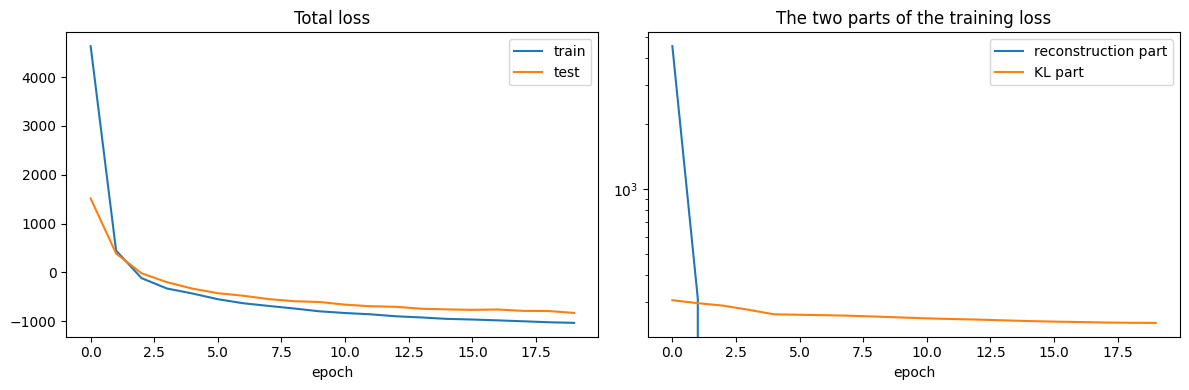

In [29]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(model.loss_during_training, label='train')
axes[0].plot(model.test_loss_during_training, label='test')
axes[0].set_title('Total loss')
axes[0].set_xlabel('epoch')
axes[0].legend()

axes[1].plot(model.rec_during_training, label='reconstruction part')
axes[1].plot(model.kl_during_training, label='KL part')
axes[1].set_title('The two parts of the training loss')
axes[1].set_xlabel('epoch')
axes[1].set_yscale('log')
axes[1].legend()

plt.tight_layout()
plt.show()

## Part 4: Looking at what the model learned

We will use 10 test pairs, one for each digit (0 to 9), in all the examples. This way we can see easily if the model gets every digit right.

In [30]:
model.eval()

# We look for the first test pair of each digit
sel_idx = [int(np.where(test_ds.mnist_labels == d)[0][0]) for d in range(10)]

x_m, x_s, y = zip(*[test_ds[i] for i in sel_idx])
x_m, x_s = torch.stack(x_m).to(device), torch.stack(x_s).to(device)
digits = list(y)

### 4.1 Reconstruction

We give **both** images of the pair to the encoders and rebuild both images. The shared part comes from the PoE of the two views, and each view keeps its own private part.

If the model works well, the reconstructions should look like the original images (a bit blurry, as always with VAEs).

Digits (left to right): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
MNIST: top row = original, bottom row = reconstruction


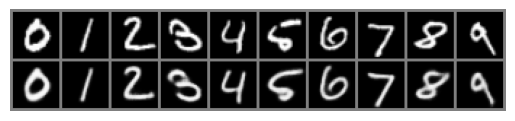

SVHN: top row = original, bottom row = reconstruction


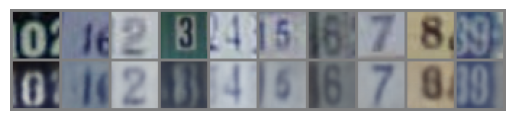

In [31]:
with torch.no_grad():
    rec_m, rec_s = model.reconstruct(x_m, x_s)

print("Digits (left to right):", digits)

print("MNIST: top row = original, bottom row = reconstruction")
grid(torch.cat([x_m, rec_m]).cpu(), nrow=10)

print("SVHN: top row = original, bottom row = reconstruction")
grid(torch.cat([x_s, rec_s]).cpu(), nrow=10)

### 4.2 Generation from the latent space

Now we do not use any input image. We sample `z_shared` from the standard normal and also one private vector for each view, and decode with **both** decoders.

The shared vector is the same for both images, so image number k in the MNIST grid and image number k in the SVHN grid should show the **same digit**. The styles are independent.

Generated MNIST images


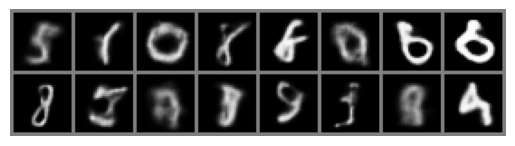

Generated SVHN images (image number k comes from the same z as image number k above)


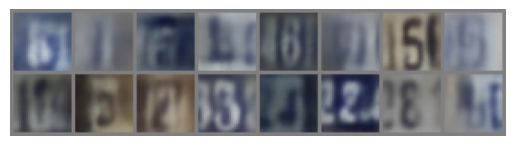

In [32]:
with torch.no_grad():
    gen_m, gen_s = model.sample(16)

print("Generated MNIST images")
grid(gen_m.cpu())

print("Generated SVHN images (image number k comes from the same z as image number k above)")
grid(gen_s.cpu())

### 4.3 Cross-domain generation

This is the most interesting part. We give the model only **one** view and ask for the **other** one.

- **MNIST → SVHN:** the shared part comes from the MNIST image, and the private part of SVHN (the style) is sampled from the prior.
- **SVHN → MNIST:** the same, in the other direction.

The last grid in each case shows a real image of the same digit, only as a reference. Do not expect the generated image to look exactly like it, because the pairs only share the label, not the style.

Digits (left to right): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
MNIST -> SVHN
MNIST input


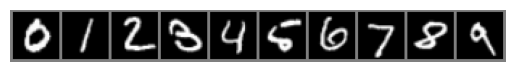

SVHN generated


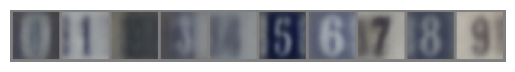

SVHN real (reference)


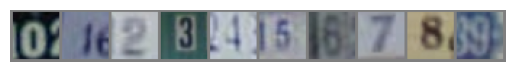

SVHN -> MNIST
SVHN input


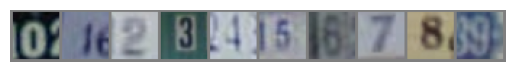

MNIST generated


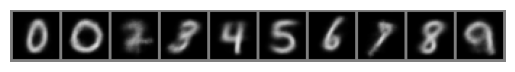

MNIST real (reference)


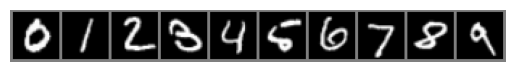

In [33]:
with torch.no_grad():
    # MNIST -> SVHN  (style of SVHN sampled from the prior)
    svhn_generated = model.translate(x_mnist=x_m)

    # SVHN -> MNIST
    mnist_generated = model.translate(x_svhn=x_s)

print("Digits (left to right):", digits)

print("MNIST -> SVHN")
print("MNIST input")
grid(x_m.cpu(), nrow=10)
print("SVHN generated")
grid(svhn_generated.cpu(), nrow=10)
print("SVHN real (reference)")
grid(x_s.cpu(), nrow=10)

print("SVHN -> MNIST")
print("SVHN input")
grid(x_s.cpu(), nrow=10)
print("MNIST generated")
grid(mnist_generated.cpu(), nrow=10)
print("MNIST real (reference)")
grid(x_m.cpu(), nrow=10)

## Part 5: Visualizing the latent space with t-SNE

The shared latent space has 32 dimensions, so we cannot plot it directly. t-SNE is a method that squeezes the points to 2D, trying to keep close points close.

We take 2000 test pairs and compute:

- `z_mnist`: the latent point we get when we give **only** the MNIST image
- `z_svhn`: the latent point we get when we give **only** the SVHN image
- `z_joint`: the latent point we get when we give **both** images

What do we hope to see? 

1. Points with the same digit should be together (clusters).
2. MNIST points and SVHN points should be **mixed** inside each cluster. That means both views really share the same latent space.

In [34]:
N_TSNE = 2000

def encode_many(n):
    z_m_list, z_s_list, z_j_list = [], [], []
    with torch.no_grad():
        for start in range(0, n, 500):
            end = min(start + 500, n)    
            xm = torch.stack([test_ds[i][0] for i in range(start, end)]).to(device)
            xs = torch.stack([test_ds[i][1] for i in range(start, end)]).to(device)

            z_m_list.append(model.encode_mean(x_mnist=xm).cpu())
            z_s_list.append(model.encode_mean(x_svhn=xs).cpu())
            z_j_list.append(model.encode_mean(x_mnist=xm, x_svhn=xs).cpu())
    return torch.cat(z_m_list).numpy(), torch.cat(z_s_list).numpy(), torch.cat(z_j_list).numpy()

z_mnist, z_svhn, z_joint = encode_many(N_TSNE)
labels_tsne = test_ds.mnist_labels[:N_TSNE]
print(z_mnist.shape, z_svhn.shape, z_joint.shape)

(2000, 32) (2000, 32) (2000, 32)


In [35]:
# t-SNE on MNIST-only and SVHN-only points together (so they share the same 2D map)
z_both_views = np.concatenate([z_mnist, z_svhn])
tsne_views = TSNE(n_components=2, init='pca', perplexity=30, random_state=0).fit_transform(z_both_views)

emb_m = tsne_views[:N_TSNE]
emb_s = tsne_views[N_TSNE:]

# t-SNE on the joint latent points
tsne_joint = TSNE(n_components=2, init='pca', perplexity=30, random_state=0).fit_transform(z_joint)

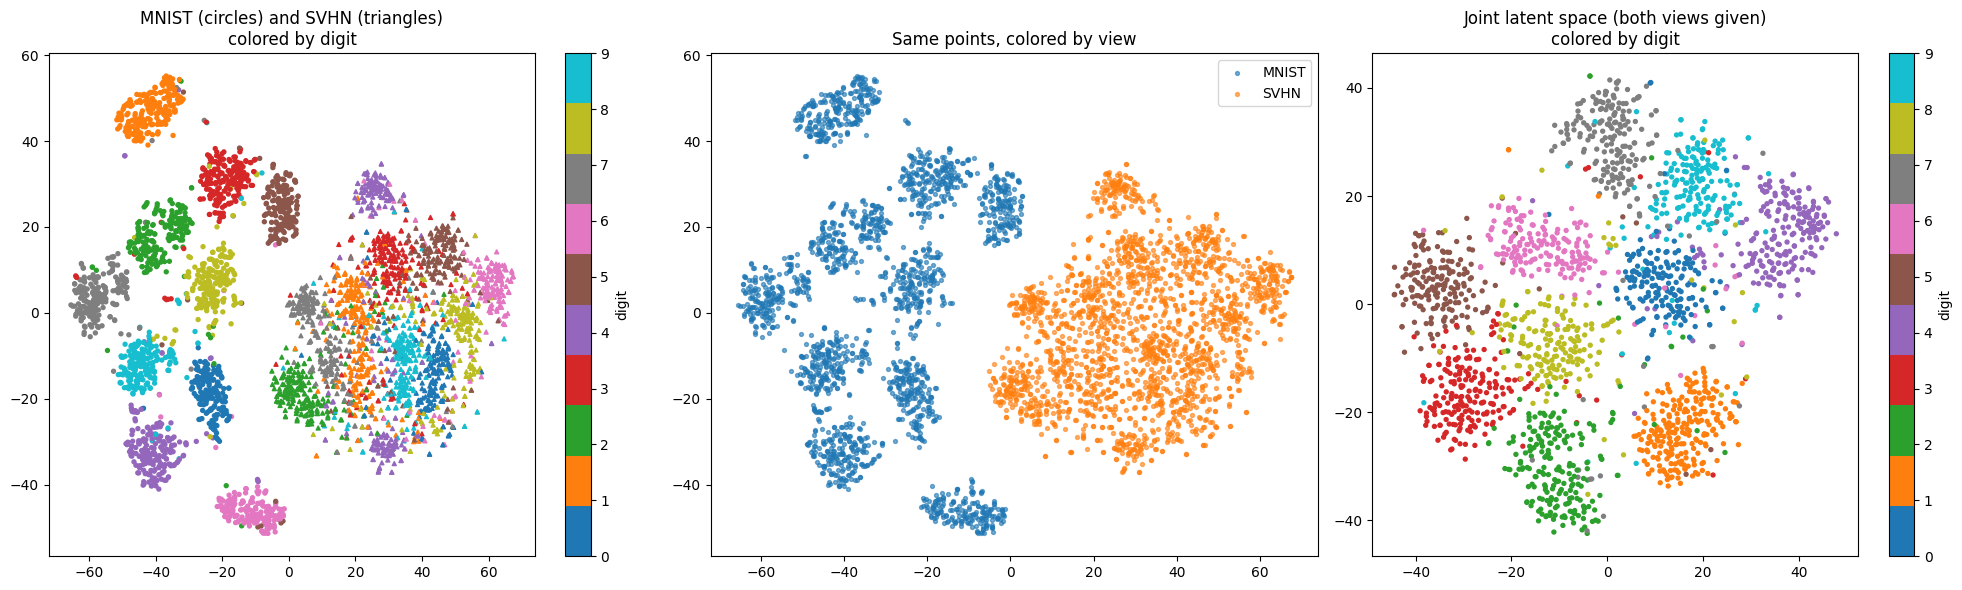

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (a) Colored by digit. Circles = MNIST, triangles = SVHN
axes[0].scatter(emb_m[:, 0], emb_m[:, 1], c=labels_tsne, cmap='tab10', s=8, marker='o')
sc = axes[0].scatter(emb_s[:, 0], emb_s[:, 1], c=labels_tsne, cmap='tab10', s=8, marker='^')
axes[0].set_title('MNIST (circles) and SVHN (triangles)\ncolored by digit')
cb = plt.colorbar(sc, ax=axes[0], ticks=range(10))
cb.set_label('digit')

# (b) Colored by view. If the two colors are well mixed, the views share the space
axes[1].scatter(emb_m[:, 0], emb_m[:, 1], s=8, c='tab:blue', alpha=0.6, label='MNIST')
axes[1].scatter(emb_s[:, 0], emb_s[:, 1], s=8, c='tab:orange', alpha=0.6, label='SVHN')
axes[1].set_title('Same points, colored by view')
axes[1].legend()

# (c) Joint latent (both images given to the model)
sc2 = axes[2].scatter(tsne_joint[:, 0], tsne_joint[:, 1], c=labels_tsne, cmap='tab10', s=8)
axes[2].set_title('Joint latent space (both views given)\ncolored by digit')
cb2 = plt.colorbar(sc2, ax=axes[2], ticks=range(10))
cb2.set_label('digit')

plt.tight_layout()
plt.show()

### t-SNE with the real images

The dots are hard to understand without knowing what each one is. So now, like in the CelebA example, we draw the **real images** at the position that t-SNE gave to each latent point. 

We use only 100 points here, because with too many images they all pile up on top of each other. If you see the same digits close together, the latent space is well organized.

In [37]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def rescale(img):
    img = img / 2 + 0.5     
    npimg = img.numpy()
    if npimg.shape[0] == 1:                 # grayscale (MNIST): repeat the channel so it is drawn in gray, not in viridis
        npimg = np.repeat(npimg, 3, axis=0)
    return np.transpose(npimg, (1, 2, 0))
 
def plot_latent_space_with_images(images,latent,xmin=-150,xmax=150,ymin=-150,ymax=150,zoom=1.0):
 
 
    f, ax = plt.subplots(1,1,figsize=(8, 8))
    ax.clear()
    for i in range(len(images)):
        im = OffsetImage(rescale(images[i,:,:,:]), zoom=zoom)   
        ab = AnnotationBbox(im, latent[i,:],frameon=False)
        ax.add_artist(ab)
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax.set_title('Latent space Z with Images')

In [38]:
N_IMG = 100

z_batch = torch.from_numpy(z_joint[:N_IMG])

# The real images of those same pairs (MNIST and SVHN), in the range [-1, 1]
imgs_mnist = torch.stack([test_ds[i][0] for i in range(N_IMG)])
imgs_svhn  = torch.stack([test_ds[i][1] for i in range(N_IMG)])

# Apply TSNE over z_batch
latent_tsne = TSNE(n_components=2, init='pca', perplexity=30, random_state=0).fit_transform(z_batch.to('cpu').detach().numpy())

# We set the plot limits using the min and max of the t-SNE points
xmin, xmax = latent_tsne[:, 0].min() - 1, latent_tsne[:, 0].max() + 1
ymin, ymax = latent_tsne[:, 1].min() - 1, latent_tsne[:, 1].max() + 1

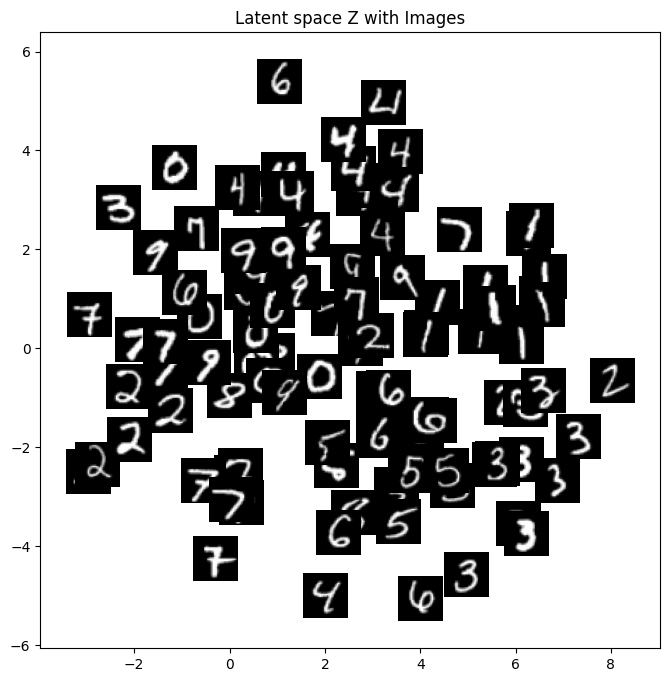

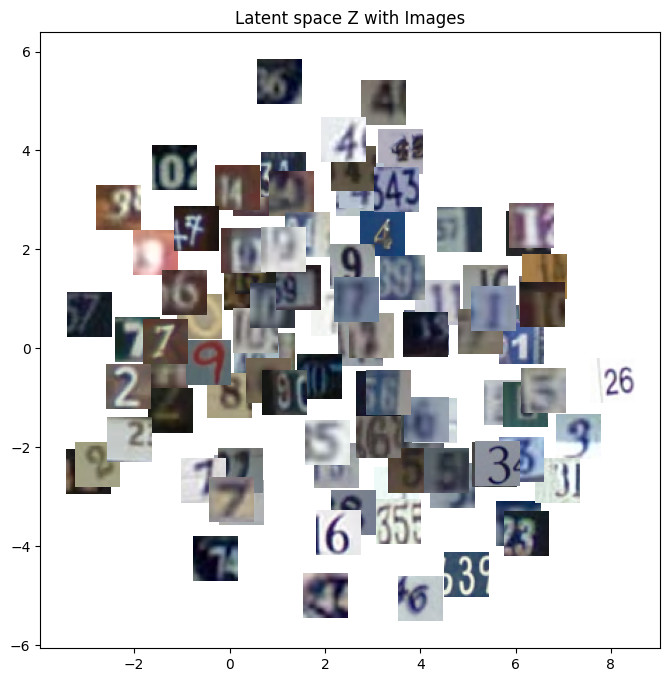

In [39]:
# The same t-SNE positions, drawn first with the MNIST images and then with the SVHN images
plot_latent_space_with_images(imgs_mnist, latent_tsne, xmin, xmax, ymin, ymax)
plt.show()

plot_latent_space_with_images(imgs_svhn, latent_tsne, xmin, xmax, ymin, ymax)
plt.show()

### A simple number to check the alignment

The plots are nice, but let's also measure something. For each MNIST latent point, we find the **closest SVHN latent point** (in the real 32-dimensional shared space, not in the t-SNE plot) and we check if both have the same digit. A high value means the two views are well aligned. A random guess would give around 10%.

In [40]:
zm = torch.from_numpy(z_mnist)
zs = torch.from_numpy(z_svhn)

dist = torch.cdist(zm, zs)                    # distance between every MNIST point and every SVHN point
nearest_svhn = dist.argmin(dim=1)             # closest SVHN point for each MNIST point
same_digit = (labels_tsne[nearest_svhn.numpy()] == labels_tsne).mean()

print(f"Closest SVHN point has the same digit as the MNIST point in {100*same_digit:.1f}% of the cases")

Closest SVHN point has the same digit as the MNIST point in 62.1% of the cases


### Coherence metrics (cross-generation and joint generation)

1-NN only looks at the shared latent space. Here we also check the **images** that the model generates, using two small CNN classifiers (`clf_mnist.pth` and `clf_svhn.pth`) trained separately on real MNIST and real SVHN.

- **Coherence M->S:** we give an MNIST test image, generate an SVHN image (style sampled from the prior), and check if the SVHN classifier says the right digit. Chance = 10%. The ceiling is the SVHN classifier accuracy on real images.
- **Coherence S->M:** the same in the other direction.
- **Joint coherence:** we sample `z_shared` and the private parts from the prior, generate one MNIST and one SVHN image, and check if both classifiers say the **same** digit.
- **1-NN M->S / S->M:** the closest point of the other view has the same digit (cell above, in both directions).
- **Clustering (leave-one-out):** the closest point **of the same view** (not counting itself) has the same digit.

First we load the classifiers and check that they reach their known test accuracy (MNIST 99.0%, SVHN 88.2%). If they do not, something is wrong with the architecture or with the input range, and the coherence numbers cannot be trusted.

In [41]:
class Classifier(nn.Module):
    # Auxiliary CNN used only to measure coherence. The layer indices match the saved weights (net.0, net.3, net.6, net.10, net.13).
    def __init__(self, in_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),            # 16 -> 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),           # 8 -> 4
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.net(x)

clf_mnist = Classifier(1).to(device)
clf_svhn = Classifier(3).to(device)
clf_mnist.load_state_dict(torch.load('clf_mnist.pth', map_location=device))
clf_svhn.load_state_dict(torch.load('clf_svhn.pth', map_location=device))
clf_mnist.eval()
clf_svhn.eval()

@torch.no_grad()
def clf_accuracy(clf, ds, to01, n=None):
    # Accuracy on a real test set. to01=True maps the images from [-1, 1] to [0, 1] before the classifier.
    ds = torch.utils.data.Subset(ds, range(n)) if n is not None else ds
    correct = 0
    for x, y in DataLoader(ds, batch_size=500, shuffle=False):
        x = x.to(device)
        if to01:
            x = (x + 1) / 2
        correct += (clf(x).argmax(dim=1).cpu() == y).sum().item()
    return correct / len(ds)

# We do not know in which range the classifiers were trained, so we try both on 2000 images and keep the best.
TO01 = {}
for name, clf, ds in [('mnist', clf_mnist, mnist_test), ('svhn', clf_svhn, svhn_test)]:
    acc_pm1 = clf_accuracy(clf, ds, to01=False, n=2000)
    acc_01 = clf_accuracy(clf, ds, to01=True, n=2000)
    TO01[name] = acc_01 > acc_pm1
    print(f"{name}: accuracy on 2000 images with input in [-1, 1] = {100*acc_pm1:.1f}%, in [0, 1] = {100*acc_01:.1f}%")

acc_m = clf_accuracy(clf_mnist, mnist_test, TO01['mnist'])
acc_s = clf_accuracy(clf_svhn, svhn_test, TO01['svhn'])
print(f"\nFull test accuracy: MNIST classifier {100*acc_m:.1f}% (expected 99.0%), SVHN classifier {100*acc_s:.1f}% (expected 88.2%)")
if abs(acc_m - 0.990) > 0.02 or abs(acc_s - 0.882) > 0.02:
    print("WARNING: the accuracy does not match the expected one. Do not trust the coherence numbers below.")

mnist: accuracy on 2000 images with input in [-1, 1] = 98.7%, in [0, 1] = 90.0%
svhn: accuracy on 2000 images with input in [-1, 1] = 87.1%, in [0, 1] = 80.5%

Full test accuracy: MNIST classifier 99.0% (expected 99.0%), SVHN classifier 88.2% (expected 88.2%)


In [42]:
N_COH = N_TSNE                       # same 2000 test pairs as in the t-SNE
labels_coh = np.asarray(labels_tsne)
torch.manual_seed(0)                 # the private style of the generated images is random

@torch.no_grad()
def predict(clf, x, to01):
    if to01:
        x = (x + 1) / 2
    return clf(x).argmax(dim=1).cpu().numpy()

# Cross-generation: M->S and S->M
pred_ms, pred_sm = [], []
with torch.no_grad():
    for start in range(0, N_COH, 500):
        end = min(start + 500, N_COH)
        xm = torch.stack([test_ds[i][0] for i in range(start, end)]).to(device)
        xs = torch.stack([test_ds[i][1] for i in range(start, end)]).to(device)
        pred_ms.append(predict(clf_svhn, model.translate(x_mnist=xm), TO01['svhn']))
        pred_sm.append(predict(clf_mnist, model.translate(x_svhn=xs), TO01['mnist']))
coh_ms = (np.concatenate(pred_ms) == labels_coh).mean()
coh_sm = (np.concatenate(pred_sm) == labels_coh).mean()

# Joint generation from the prior: do both generated images show the same digit?
pred_gm, pred_gs = [], []
with torch.no_grad():
    for _ in range(N_COH // 500):
        xm_g, xs_g = model.sample(500)
        pred_gm.append(predict(clf_mnist, xm_g, TO01['mnist']))
        pred_gs.append(predict(clf_svhn, xs_g, TO01['svhn']))
coh_joint = (np.concatenate(pred_gm) == np.concatenate(pred_gs)).mean()

# 1-NN in both directions (the shared latent means computed in the t-SNE section)
zm = torch.from_numpy(z_mnist)
zs = torch.from_numpy(z_svhn)
dist = torch.cdist(zm, zs)
nn_ms = (labels_coh[dist.argmin(dim=1).numpy()] == labels_coh).mean()   # for each MNIST point, closest SVHN point
nn_sm = (labels_coh[dist.argmin(dim=0).numpy()] == labels_coh).mean()   # for each SVHN point, closest MNIST point

# Clustering inside each view (leave-one-out)
def loo_knn(z):
    d = torch.cdist(z, z)
    d.fill_diagonal_(float('inf'))                 # a point cannot be its own neighbour
    return (labels_coh[d.argmin(dim=1).numpy()] == labels_coh).mean()
loo_m = loo_knn(zm)
loo_s = loo_knn(zs)

print(f"Model: {model.mode.upper()}, missing_private='{model.missing_private}', shared={model.ds}, private MNIST={model.dp_m}, private SVHN={model.dp_s}   ({N_COH} test pairs)")
print(f"Coherence M->S : {100*coh_ms:5.1f}%   (chance 10%, ceiling {100*acc_s:.1f}%)")
print(f"Coherence S->M : {100*coh_sm:5.1f}%   (chance 10%, ceiling {100*acc_m:.1f}%)")
print(f"Coherence joint: {100*coh_joint:5.1f}%   (chance about 10%)")
print(f"1-NN M->S      : {100*nn_ms:5.1f}%")
print(f"1-NN S->M      : {100*nn_sm:5.1f}%")
print(f"Clustering LOO : MNIST {100*loo_m:.1f}% / SVHN {100*loo_s:.1f}%")

Model: POE, missing_private='cross', shared=32, private MNIST=1, private SVHN=4   (2000 test pairs)
Coherence M->S :  79.7%   (chance 10%, ceiling 88.2%)
Coherence S->M :  61.3%   (chance 10%, ceiling 99.0%)
Coherence joint:  24.8%   (chance about 10%)
1-NN M->S      :  62.1%
1-NN S->M      :  71.7%
Clustering LOO : MNIST 94.7% / SVHN 74.1%


## Final notes and conclusions

In this lab we trained a multi-view VAE with a Product of Experts (PoE) on 60,000 MNIST–SVHN training pairs that share only the digit label. The model has a shared latent space of 32 dimensions and a small private latent per view (1 number for MNIST, 4 for SVHN). During the 20 epochs the training loss went from 4636.0 to -1035.0 and the test loss reached -831.1. The test loss kept going down during the whole training, but it stays above the training loss, so there is a generalization gap, and the model had not fully converged at epoch 20. The loss is negative because of the constant of the Gaussian likelihood, so only its trend is meaningful, and it cannot be compared with models that have a different `var_x` or different latent sizes.

**Reconstruction and generation.** MNIST reconstructions are accurate. SVHN reconstructions recover the colour and background of each image, but they are blurrier and some digits are hard to read, which is expected for a VAE with a Gaussian likelihood on complex images. In cross-domain generation, SVHN → MNIST gives readable digits, but not always the right one (for example, a 1 can come out as a 0). MNIST → SVHN gives plausible colours and backgrounds, but several digits are faint.

**Quantitative results (2,000 test pairs, chance = 10%).** We compare the final model with the first version (v1: PoE, latent of 20 numbers, no private latent, 20 epochs).

| Metric | v1 | Final model |
|---|---|---|
| Coherence MNIST → SVHN (ceiling 88.2%) | 14.2% | **79.7%** |
| Coherence SVHN → MNIST (ceiling 99.0%) | **82.8%** | 61.3% |
| Joint coherence | 25.7% | 24.8% |
| 1-NN MNIST → SVHN / SVHN → MNIST | 22.4% / 27.2% | **62.1% / 71.7%** |
| Clustering leave-one-out MNIST / SVHN | 93.4% / 74.2% | 94.7% / 74.1% |

MNIST → SVHN, the 1-NN and the clustering are far above chance, and MNIST → SVHN is close to its ceiling. The joint coherence is modest (about 2.5 times the chance level) and it did not improve over v1. SVHN → MNIST is **lower** than in v1 (82.8%) and than in a PoE checkpoint with a latent of 50 numbers (86.1%), so the final model trades some SVHN → MNIST accuracy for a working MNIST → SVHN. A possible reason is that the SVHN encoder carries less information about the digit, but the clustering of SVHN is the same as in v1 (74.1% vs 74.2%), so this alone does not explain the drop.

**How we solved the gray SVHN.** Our first versions generated an almost uniform gray SVHN image from MNIST (coherence 14.2%). Changing the variance of the likelihood, adding KL annealing, training more epochs, using a bigger latent or switching between PoE and MoE did not help. The reason is in the objective: since the pairs only share the digit, the best answer for a Gaussian with fixed variance, given only the MNIST image, is the average of all the SVHN images of that digit, and that average is almost gray. What worked was to give the style its own place:

1. We split the latent into a shared part and a private part for each view. Filling the private part of the missing view with random noise or with the code of another image (`'prior'`, `'shuffle'`) did not fix MNIST → SVHN.
2. Rebuilding each image with the private code of its real pair (the `'cross'` option, in the style of the DMVAE) did give colours and backgrounds, but the size of the private part was critical. With 16 numbers the digit moved into the private part and the 1-NN fell to chance (11.8%). With 4 numbers in both views, MNIST → SVHN worked (71.5%) but SVHN → MNIST fell to chance (11.8%).
3. MNIST has almost no style, so it only needs a very small private part. With 1 number for MNIST and 4 for SVHN, the digit cannot hide in the private code, and both directions work.

**PoE and MoE.** We only compared them on checkpoints with a latent of 50 numbers: PoE aligned the two views better (1-NN 44.2% vs 30.9%), while MoE reconstructs SVHN from its own encoder slightly better (MSE 0.0065 vs 0.0111). The apparent failure of MoE in our first evaluation was an evaluation problem: averaging the means of the two experts gives a point that MoE never sees in training. We did not retrain MoE with the final configuration, which uses PoE.

**Latent space.** In the t-SNE of the joint space (both images given), the ten digits form clear clusters. When each view is encoded alone, MNIST forms tight clusters, and SVHN is more spread out but also grouped by digit. However, the two views mostly occupy different regions of the plot, so the alignment is only partial.

**Limitations and difficulties.** The hardest part was making the model work for SVHN, which is much more complex than MNIST (colour, varied backgrounds and fonts, distracting digits). Joint generation from the prior is not good yet (24.8%). A possible reason is that samples of `z_shared` do not always fall where the encoders place real data, so the two decoders do not always draw the same digit, but we did not measure this. All the results come from one training run on 2,000 test pairs, so we have no error bars, and the weight of the alignment term (`align_weight = 1.0`) was never tuned.

